In [1]:
# -------------------------------------------
# 
# plot GCAM and SCEPTER derived CDR estimates
# 
# -------------------------------------------
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

In [2]:
# --- read in data
#
#  ----------------------------------------------------------------
# [ RUN NAMES ]
# exe_central1p5 ; exe_central2p0 ; exe_limBio1p5 ; exe_lowCCS1p5 ; 
# exe_lowCDR1p5 ; exe_noBiochar1p5 ; exe_noWeathering1p5 ; 
# exe_ref1p5 ; exe_techBehaviorChange1p5 ; exe_techBehaviorChange2p0 ;
# ----------------------------------------------------------------
#
# ************************************************
# --- SCEPTER outputs
EXP_GROUP = "gcam_opr_psdfull_nocec"
EXP_SET = 'exe_central1p5'
idx = "001"
dir_postproc = f's3://carbonplan-carbon-removal/ew-workflows-data/scepter/postprocessed/{EXP_GROUP}/{EXP_SET}_{idx}'
fn_cdr = "ds_cdr.zarr"   # time-integrated data
fn_cdr_trans = "ds_cdr_transient.zarr"  # time-transient data
# [ read in ]
ds = xr.open_zarr(os.path.join(dir_postproc, fn_cdr))
ds_trans = xr.open_zarr(os.path.join(dir_postproc, fn_cdr_trans))

# ************************************************
# --- GCAM outputs
run_format = 'one-cell-per-region'
deg_resolution = 1
gcam_dir = f's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/{run_format}/{EXP_SET}'
gcam_fn = f'annual_rockflx_densest-ag-region_{deg_resolution}deg.pkl'
# [ read in ]
df = pd.read_pickle(os.path.join(gcam_dir, gcam_fn))

# ************************************************
# --- derived ag map 
run_format = 'one-cell-per-region'
deg_resolution = 1
gcam_dir = f's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/{run_format}/{EXP_SET}'
gcam_fn = f'cropland+gcamRegions_time_{deg_resolution}deg.zarr'
# [ read in ]
dsag = xr.open_zarr(os.path.join(gcam_dir, gcam_fn))

In [3]:
# --- compute global GCAM CDR 
df_global = (
    df.groupby("time", as_index=False)["gcam_gross_cdr_mtCO2"]
      .sum()
      .assign(region="globe")
)

## Calculate global CDR from SCEPTER outputs
Each pixel (or site) in SCEPTER outputs CDR in tonnes/ha. If we have one pixel per region, then we need to muliply by the cropland area in the region to get the total tonnes. 

Note that the cropland area units are m2. 1 ha = 1 m2/1000.

In [4]:
# [ list vars to scale by area ] -----------------------
vars_to_scale_by_area = [
    'cdr_adv', 'cdr_adv_plus_newSIC', 'cdr_dif', 'cdr_dif_component',
    'cdr_resp_component', 'cdr_resp_component_noAE', 'cdr_SIConly', 
    'co2pot_adv_tonHa_camg', 'co2pot_adv_tonHa_totcat', 'co2pot_tot_tonHa_camg',
    'co2pot_tot_tonHa_totcat', 'DICpot_adv_camg', 'DICpot_adv_totcat',
    'int_dust_ton_ha_yr', 
]
vars_to_scale_by_area_trans = [
    'cdr_adv', 'cdr_adv_plus_newSIC', 'cdr_dif', 'cdr_dif_component',
    'cdr_resp_component', 'cdr_resp_component_noAE', 'cdr_SIConly', 
    'co2pot_adv_tonHaYr_camg', 'co2pot_adv_tonHaYr_totcat', 'co2pot_tot_tonHaYr_camg',
    'co2pot_tot_tonHaYr_totcat', 'DICpot_adv_camg', 'DICpot_adv_totcat',
    'int_dust_ton_ha_yr', 
]
# ------------------------------------------------------
# 
# --- calculate global annual CDR 
# [ get cropland area for each region ]
dfreg_t0 = df.groupby("region", as_index=False).first().copy() # df of regional data (1 row / region, no time)
dfreg_t0['cropland_area_by_region'] = dsag["cropland_area_by_region"].sel(
    y=xr.DataArray(dfreg_t0["lat"].values, dims="points"),
    x=xr.DataArray(dfreg_t0["lon"].values, dims="points"),
)
# convert area from m2 to hectares
dfreg_t0['cropland_area_by_region_hectares'] = dfreg_t0['cropland_area_by_region'] / 1e4
# align df regions to ds sites for later calculation
area_series = (
    dfreg_t0.set_index("region_nospaces")["cropland_area_by_region_hectares"]
)
area_series.index.name = "site"
area_da = xr.DataArray(
    area_series,
    dims="site",
    coords={"site": area_series.index}
)
# 
# =========================================================================
for var in vars_to_scale_by_area:
    # [ calculate vars in tonnes / yr for each region (multiply by hectares) ]
    ds[f'{var}_xCropArea'] = ds[var] * area_da
    ds[f'{var}_xCropArea'].attrs['note'] = f"Var {var} multiplied by regional hectares of cropland"
for var_trans in vars_to_scale_by_area_trans:
    # [ repeat for transient data ]
    ds_trans[f'{var_trans}_xCropArea'] = ds_trans[var_trans] * area_da
    ds_trans[f'{var_trans}_xCropArea'].attrs['note'] = f"Var {var_trans} multiplied by regional hectares of cropland"

In [5]:
# --- apply rock feedstock RCO2 correction
cdr_vars = [
    'cdr_adv', 'cdr_adv_plus_newSIC', 'cdr_dif', 'cdr_dif_component',
    'cdr_resp_component', 'cdr_resp_component_noAE', 'cdr_SIConly', 
    'co2pot_adv_tonHa_camg', 'co2pot_adv_tonHa_totcat', 'co2pot_tot_tonHa_camg',
    'co2pot_tot_tonHa_totcat', 'DICpot_adv_camg', 'DICpot_adv_totcat',
]
cdr_vars_trans = [
    'cdr_adv', 'cdr_adv_plus_newSIC', 'cdr_dif', 'cdr_dif_component',
    'cdr_resp_component', 'cdr_resp_component_noAE', 'cdr_SIConly', 
    'co2pot_adv_tonHaYr_camg', 'co2pot_adv_tonHaYr_totcat', 'co2pot_tot_tonHaYr_camg',
    'co2pot_tot_tonHaYr_totcat', 'DICpot_adv_camg', 'DICpot_adv_totcat',
]
# =========================================================================
rco2_gcam = 0.3
rco2_gbas = 0.41
corr_factor = rco2_gcam / rco2_gbas
for var in vars_to_scale_by_area:
    # [ calculate vars in tonnes / yr for each region (multiply by hectares) ]
    ds[f'{var}_xCropArea_corr'] = ds[f'{var}_xCropArea'] * corr_factor
    ds[f'{var}_xCropArea_corr'].attrs['note'] = f"Var {var} multiplied by regional hectares of cropland and corrected for different feedstock RCO2 compared to gcam"
for var_trans in vars_to_scale_by_area_trans:
    # [ repeat for transient data ]
    ds_trans[f'{var_trans}_xCropArea_corr'] = ds_trans[f'{var_trans}_xCropArea'] * corr_factor
    ds_trans[f'{var_trans}_xCropArea_corr'].attrs['note'] = f"Var {var} multiplied by regional hectares of cropland and corrected for different feedstock RCO2 compared to gcam"

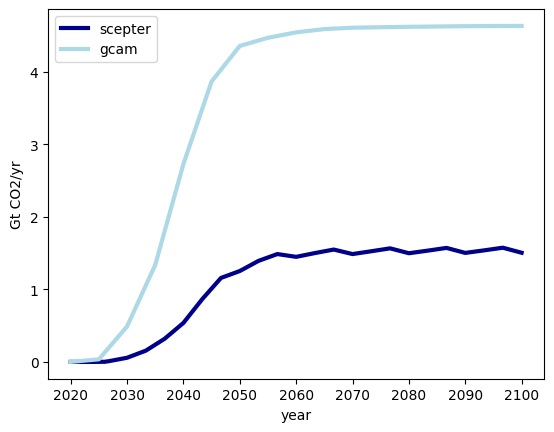

In [6]:
# [ get global sum of CDR ]

plt.plot(ds_trans.time+2020, ds_trans['cdr_adv_xCropArea_corr'].sum('site')/1e9, label='scepter', c='darkblue', linewidth=3)
plt.plot(df_global['time'], df_global['gcam_gross_cdr_mtCO2']/1e3, label='gcam', c='lightblue', linewidth=3)
plt.xlabel('year')
plt.ylabel('Gt CO2/yr')
plt.legend()

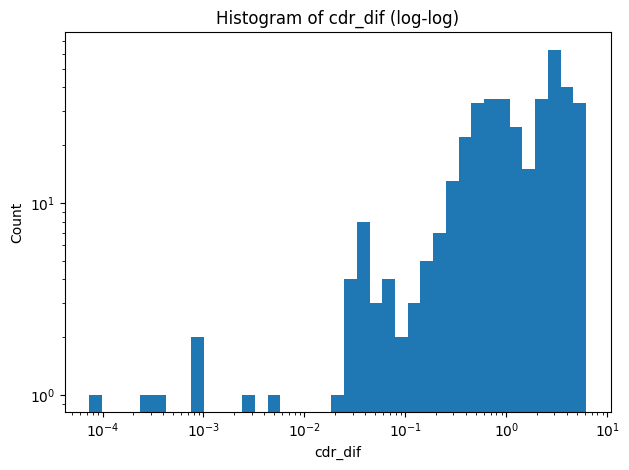

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Flatten and remove non-positive values (required for log scale)
data = ds_trans['cdr_dif'].values.flatten()
data = data[np.isfinite(data)]
data = data[data > 0]

# Create log-spaced bins
bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 40)

# Plot
plt.figure()
plt.hist(data, bins=bins)

plt.xscale("log")      # log x-axis
plt.yscale("log")      # log bar heights
plt.xlabel("cdr_dif")
plt.ylabel("Count")
plt.title("Histogram of cdr_dif")
plt.tight_layout()
plt.show()

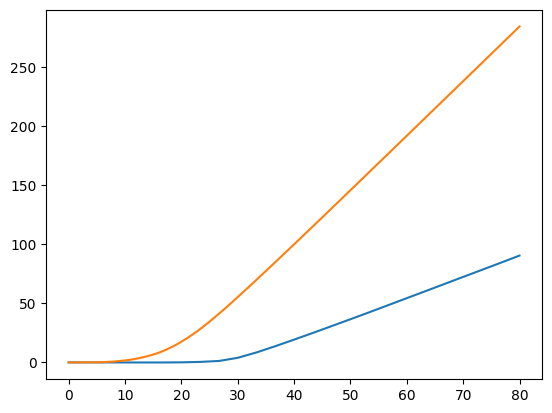

In [70]:
plt.plot(ds.time, ds['cdr_adv_xCropArea_corr'].sum('site')/1e9)
plt.plot(df_global['time']-df_global['time'].values[0], df_global['gcam_gross_cdr_mtCO2'].cumsum()/1e3)

In [36]:
# very rough back of envelope
assumed_rock_mass_to_neutralize_spr = 50 # [t / ha]
carea_m2 = dsag['cropland_area'].sum().values # [m2]
carea_ha = carea_m2 / 1e4   # [ha]
total_mass_needed_tonne = assumed_rock_mass_to_neutralize_spr * carea_ha # [tonne]
total_mass_needed_Gt = total_mass_needed_tonne / 1e9 # [Gt]
print(f"rough estimate of rock needed to neutralize SPR:\n {total_mass_needed_Gt} Gt")

rough estimate of rock needed to neutralize SPR:
 74.27319581383817 Gt


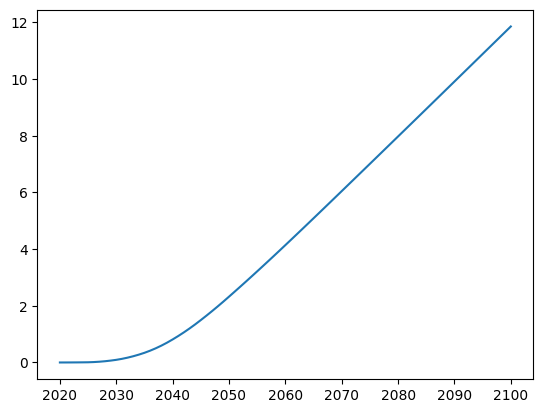

In [27]:
# [ how much rock applied before ~2040 (to eliminate SPR) ]
# --- compute global rock amounts
df_global_rock = (
    df.groupby("time", as_index=False)["rockflx_Mt"]
      .sum()
      .assign(region="globe")
)
# plt.plot(df_global_rock['time'], df_global_rock['rockflx_Mt'])
plt.plot(df_global_rock['time'], df_global_rock['rockflx_Mt'].cumsum()/1e3)

Text(0.5, 1.0, 'USA')

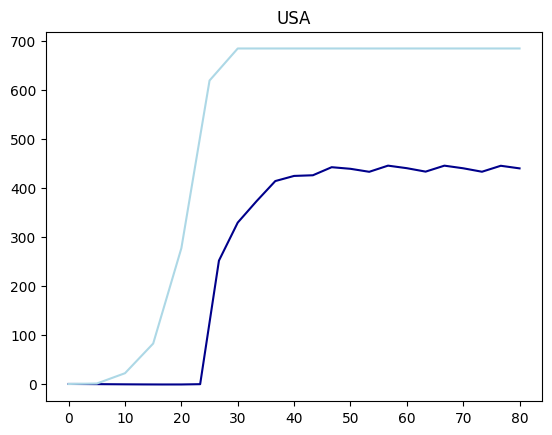

In [71]:
allsites = ds.site.values
thissite = allsites[31]

tds = ds_trans.sel(site=thissite)
tdf = df[df['region_nospaces'] == thissite] 
plt.plot(tds.time, tds['cdr_adv_xCropArea_corr'] / 1e6, c='darkblue')
plt.plot(tdf['time']-2020, tdf['gcam_gross_cdr_mtCO2'], c='lightblue')
plt.title(thissite)

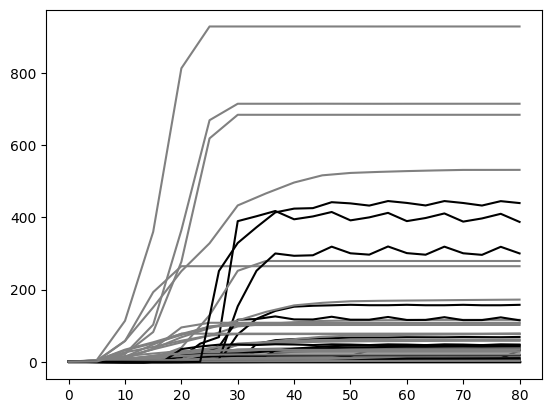

In [72]:
allsites = ds.site.values

for site in allsites:
    tds = ds_trans.sel(site=site)
    tdf = df[df['region_nospaces'] == site] 
    plt.plot(tds.time, tds['cdr_adv_xCropArea_corr'] / 1e6, c='black')
    plt.plot(tdf['time']-2020, tdf['gcam_gross_cdr_mtCO2'], c='gray')

In [ ]:
# dfreg_t0['region_nospaces']
set(ds.site.values) - set(area_series.index)

{'Africa_Eastern',
 'Africa_Northern',
 'Africa_Southern',
 'Africa_Western',
 'Argentina',
 'Australia_NZ',
 'Brazil',
 'Canada',
 'Central_America_and_Caribbean',
 'Central_Asia',
 'China',
 'Colombia',
 'EU-12',
 'EU-15',
 'Europe_Eastern',
 'Europe_Non_EU',
 'European_Free_Trade_Association',
 'India',
 'Indonesia',
 'Japan',
 'Mexico',
 'Middle_East',
 'Pakistan',
 'Russia',
 'South_Africa',
 'South_America_Northern',
 'South_America_Southern',
 'South_Asia',
 'South_Korea',
 'Southeast_Asia',
 'Taiwan',
 'USA'}